# Classificação da qualidade de vinhos com Machine Learning

Tech Challenge - Fase 2 | Pós Tech FIAP

A qualidade de um vinho normalmente é avaliada por especialistas, em uma análise sensorial que é subjetiva e demorada. Por outro lado, durante a produção já são medidas várias características físico-químicas do vinho. A ideia deste trabalho é usar essas medições para prever se um vinho vai ser considerado de alta qualidade, ajudando enólogos e produtores a tomar decisões ainda no processo.

Etapas do notebook:

1. Compreensão do problema
2. Análise exploratória dos dados
3. Pré-processamento
4. Modelos (KNN, Regressão Logística e Random Forest)
5. Avaliação dos modelos
6. Interpretação dos resultados
7. Conclusão

In [1]:
# No Colab, monta o Drive e entra na pasta do projeto. Localmente, sobe da pasta notebooks/
import os
import sys

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/wine-quality-classification')
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

sys.path.append(os.getcwd())

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             classification_report, confusion_matrix)
from sklearn.model_selection import GridSearchCV, cross_validate, train_test_split

from src.preprocessing import (ENGINEERED_FEATURES, FEATURE_LABELS, FEATURES, QUALITY_THRESHOLD,
                               add_engineered_features, check_inconsistencies, create_target,
                               iqr_outliers, load_data, remove_duplicates)
from src.modeling import (METRIC_NAMES, RANDOM_STATE, SCALERS, SCORING, cv_summary, evaluate,
                          get_cv, knn_pipeline, logreg_pipeline, rf_pipeline)

pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid')

FIG_DIR = 'results/figures'
os.makedirs(FIG_DIR, exist_ok=True)

CLASSES = ['Baixa/Média (< 7)', 'Alta (>= 7)']
COLORS = {0: '#9e9e9e', 1: '#7b1e3a'}


def save_fig(fig, name):
    fig.savefig(f'{FIG_DIR}/{name}.png', bbox_inches='tight', dpi=150)

## 1. Compreensão do problema

Usamos o [Wine Quality Dataset](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset) do Kaggle (arquivo `WineQT.csv`). Cada linha é um vinho tinto com 11 medições físico-químicas, a nota dada pelos especialistas (`quality`) e um identificador (`Id`).

In [3]:
raw = load_data()
print(raw.shape)
raw.head()

(1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5,0
1,7.8000,0.8800,0.0000,2.6000,0.0980,25.0000,67.0000,0.9968,3.2000,0.6800,9.8000,5,1
2,7.8000,0.7600,0.0400,2.3000,0.0920,15.0000,54.0000,0.9970,3.2600,0.6500,9.8000,5,2
3,11.2000,0.2800,0.5600,1.9000,0.0750,17.0000,60.0000,0.9980,3.1600,0.5800,9.8000,6,3
4,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5,4


In [4]:
pd.DataFrame({'variável': FEATURES, 'descrição': [FEATURE_LABELS[f] for f in FEATURES]})

,variável,descrição
0,fixed acidity,Acidez fixa (g/L)
1,volatile acidity,Acidez volátil (g/L)
2,citric acid,Ácido cítrico (g/L)
3,residual sugar,Açúcar residual (g/L)
4,chlorides,Cloretos (g/L)
5,free sulfur dioxide,SO2 livre (mg/L)
6,total sulfur dioxide,SO2 total (mg/L)
7,density,Densidade (g/cm³)
8,pH,pH
9,sulphates,Sulfatos (g/L)


### Variável alvo

A nota `quality` vai de 0 a 10. Como o objetivo é identificar os vinhos que se destacam, transformamos a nota em duas classes:

- alta qualidade (1): nota maior ou igual a 7
- baixa/média qualidade (0): nota menor que 7

A nova coluna se chama `high_quality`. A coluna `quality` não entra como variável de entrada, já que ela é a própria resposta.

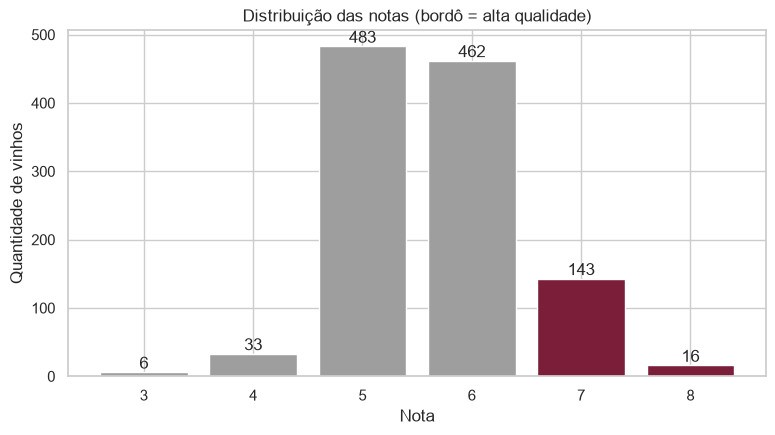

In [5]:
counts = raw['quality'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(counts.index.astype(str), counts.values,
              color=[COLORS[int(q >= QUALITY_THRESHOLD)] for q in counts.index])
ax.bar_label(bars)
ax.set_title('Distribuição das notas (bordô = alta qualidade)')
ax.set_xlabel('Nota')
ax.set_ylabel('Quantidade de vinhos')
save_fig(fig, '01_distribuicao_notas')
plt.show()

In [6]:
raw = create_target(raw)
raw[['quality', 'high_quality']].value_counts().sort_index()

quality  high_quality
3        0                 6
4        0                33
5        0               483
6        0               462
7        1               143
8        1                16
Name: count, dtype: int64

As notas ficam concentradas em 5 e 6 e não aparecem notas abaixo de 3 nem acima de 8. Com o corte em 7, a classe de alta qualidade fica bem menor que a outra, o que vamos ter que levar em conta na modelagem.

## 2. Análise exploratória

### Estrutura dos dados

In [7]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
 13  high_quality          1143 non-null   int64  
dtypes: float64(11), int64(3)
memory usage: 125.1 KB


In [8]:
raw[FEATURES + ['quality']].describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0000,8.3111,1.7476,4.6000,7.1000,7.9000,9.1000,15.9000
volatile acidity,1143.0000,0.5313,0.1796,0.1200,0.3925,0.5200,0.6400,1.5800
citric acid,1143.0000,0.2684,0.1967,0.0000,0.0900,0.2500,0.4200,1.0000
residual sugar,1143.0000,2.5322,1.3559,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1143.0000,0.0869,0.0473,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1143.0000,15.6155,10.2505,1.0000,7.0000,13.0000,21.0000,68.0000
total sulfur dioxide,1143.0000,45.9147,32.7821,6.0000,21.0000,37.0000,61.0000,289.0000
density,1143.0000,0.9967,0.0019,0.9901,0.9956,0.9967,0.9978,1.0037
pH,1143.0000,3.3110,0.1567,2.7400,3.2050,3.3100,3.4000,4.0100
sulphates,1143.0000,0.6577,0.1704,0.3300,0.5500,0.6200,0.7300,2.0000


### Dados faltantes e duplicados

In [9]:
print('Valores faltantes:', raw.isna().sum().sum())

n_dup = raw.duplicated(subset=FEATURES + ['quality']).sum()
print(f'Linhas duplicadas (ignorando o Id): {n_dup} ({n_dup / len(raw):.1%})')

Valores faltantes: 0
Linhas duplicadas (ignorando o Id): 125 (10.9%)


Não há valores faltantes. Já as duplicadas são 125 linhas com as mesmas medições e a mesma nota, mudando só o `Id`, ou seja, é o mesmo vinho registrado mais de uma vez. Removemos essas linhas porque, se uma cópia ficasse no treino e outra no teste, o modelo seria testado em um vinho que ele já viu e as métricas ficariam melhores do que realmente são (vazamento de dados). A coluna `Id` também sai, porque não tem significado químico.

In [10]:
df = remove_duplicates(raw).drop(columns='Id')
print('Linhas após remover duplicadas:', len(df))

Linhas após remover duplicadas: 1018


### Valores inconsistentes

Conferimos algumas regras que qualquer vinho deveria respeitar.

In [11]:
check_inconsistencies(df)

,regra,ocorrencias
0,valores negativos,0
1,SO2 livre maior que SO2 total,0
2,ácido cítrico maior que acidez fixa,0
3,"pH fora de 2,5 a 4,5",0
4,"densidade fora de 0,98 a 1,01",0
5,álcool fora de 5% a 16%,0
6,nota fora de 0 a 10,0


Nenhuma regra foi violada. Os valores extremos que aparecem mais à frente são raros, mas possíveis.

### Distribuição das variáveis

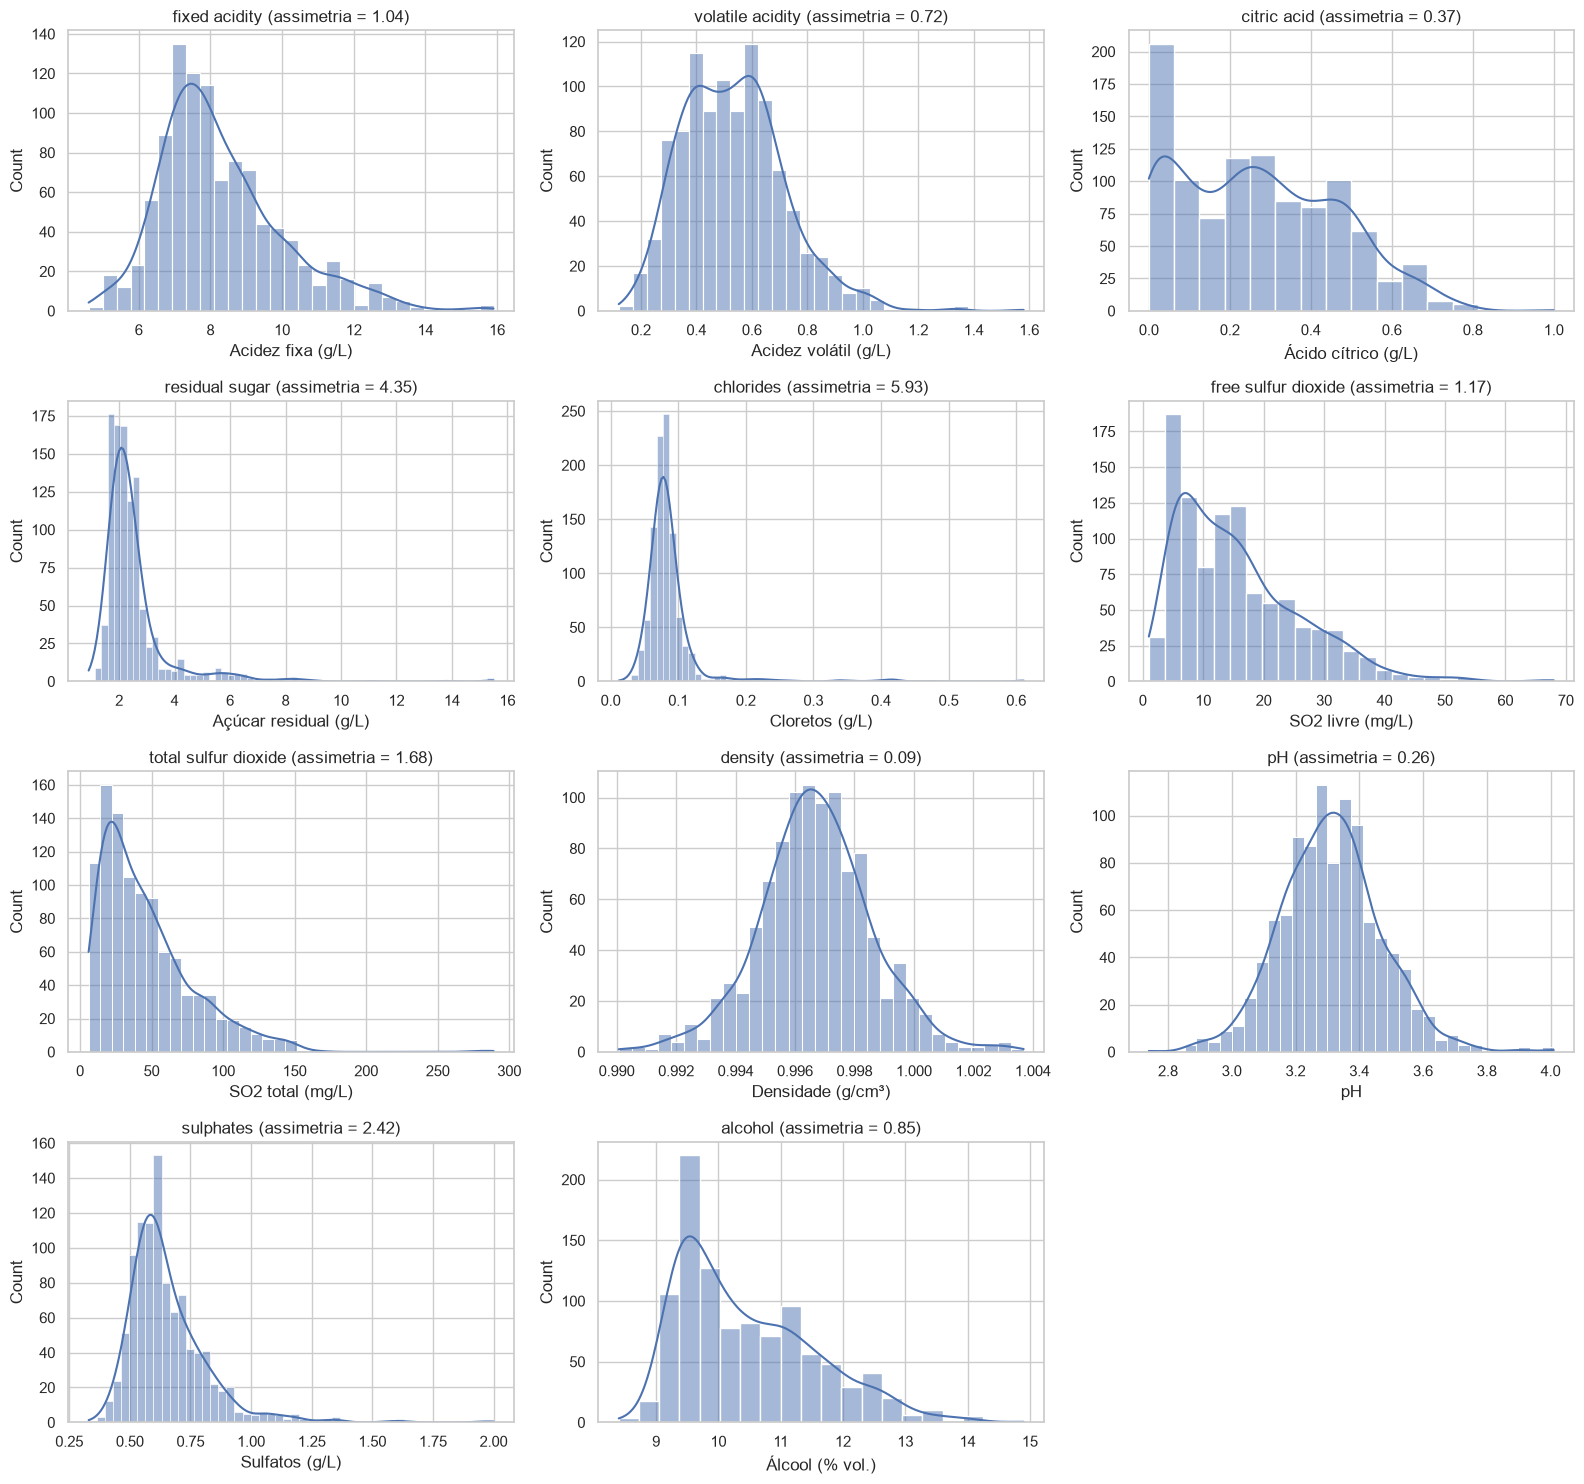

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f'{col} (assimetria = {df[col].skew():.2f})')
    ax.set_xlabel(FEATURE_LABELS[col])
axes.flat[-1].axis('off')
fig.tight_layout()
save_fig(fig, '02_distribuicoes')
plt.show()

Densidade e pH têm distribuição praticamente simétrica. A maioria das outras variáveis tem cauda à direita, e em cloretos (assimetria 5,9), açúcar residual (4,3) e sulfatos (2,4) isso é bem forte: quase todos os vinhos têm valores baixos e poucos têm valores muito altos.

As escalas também são muito diferentes entre si (a densidade fica perto de 0,99 e o SO2 total chega a 289). Por isso vamos precisar escalonar os dados para o KNN e para a Regressão Logística.

### Outliers

Usamos o critério do intervalo interquartil (IQR): é outlier o valor abaixo de Q1 - 1,5*IQR ou acima de Q3 + 1,5*IQR.

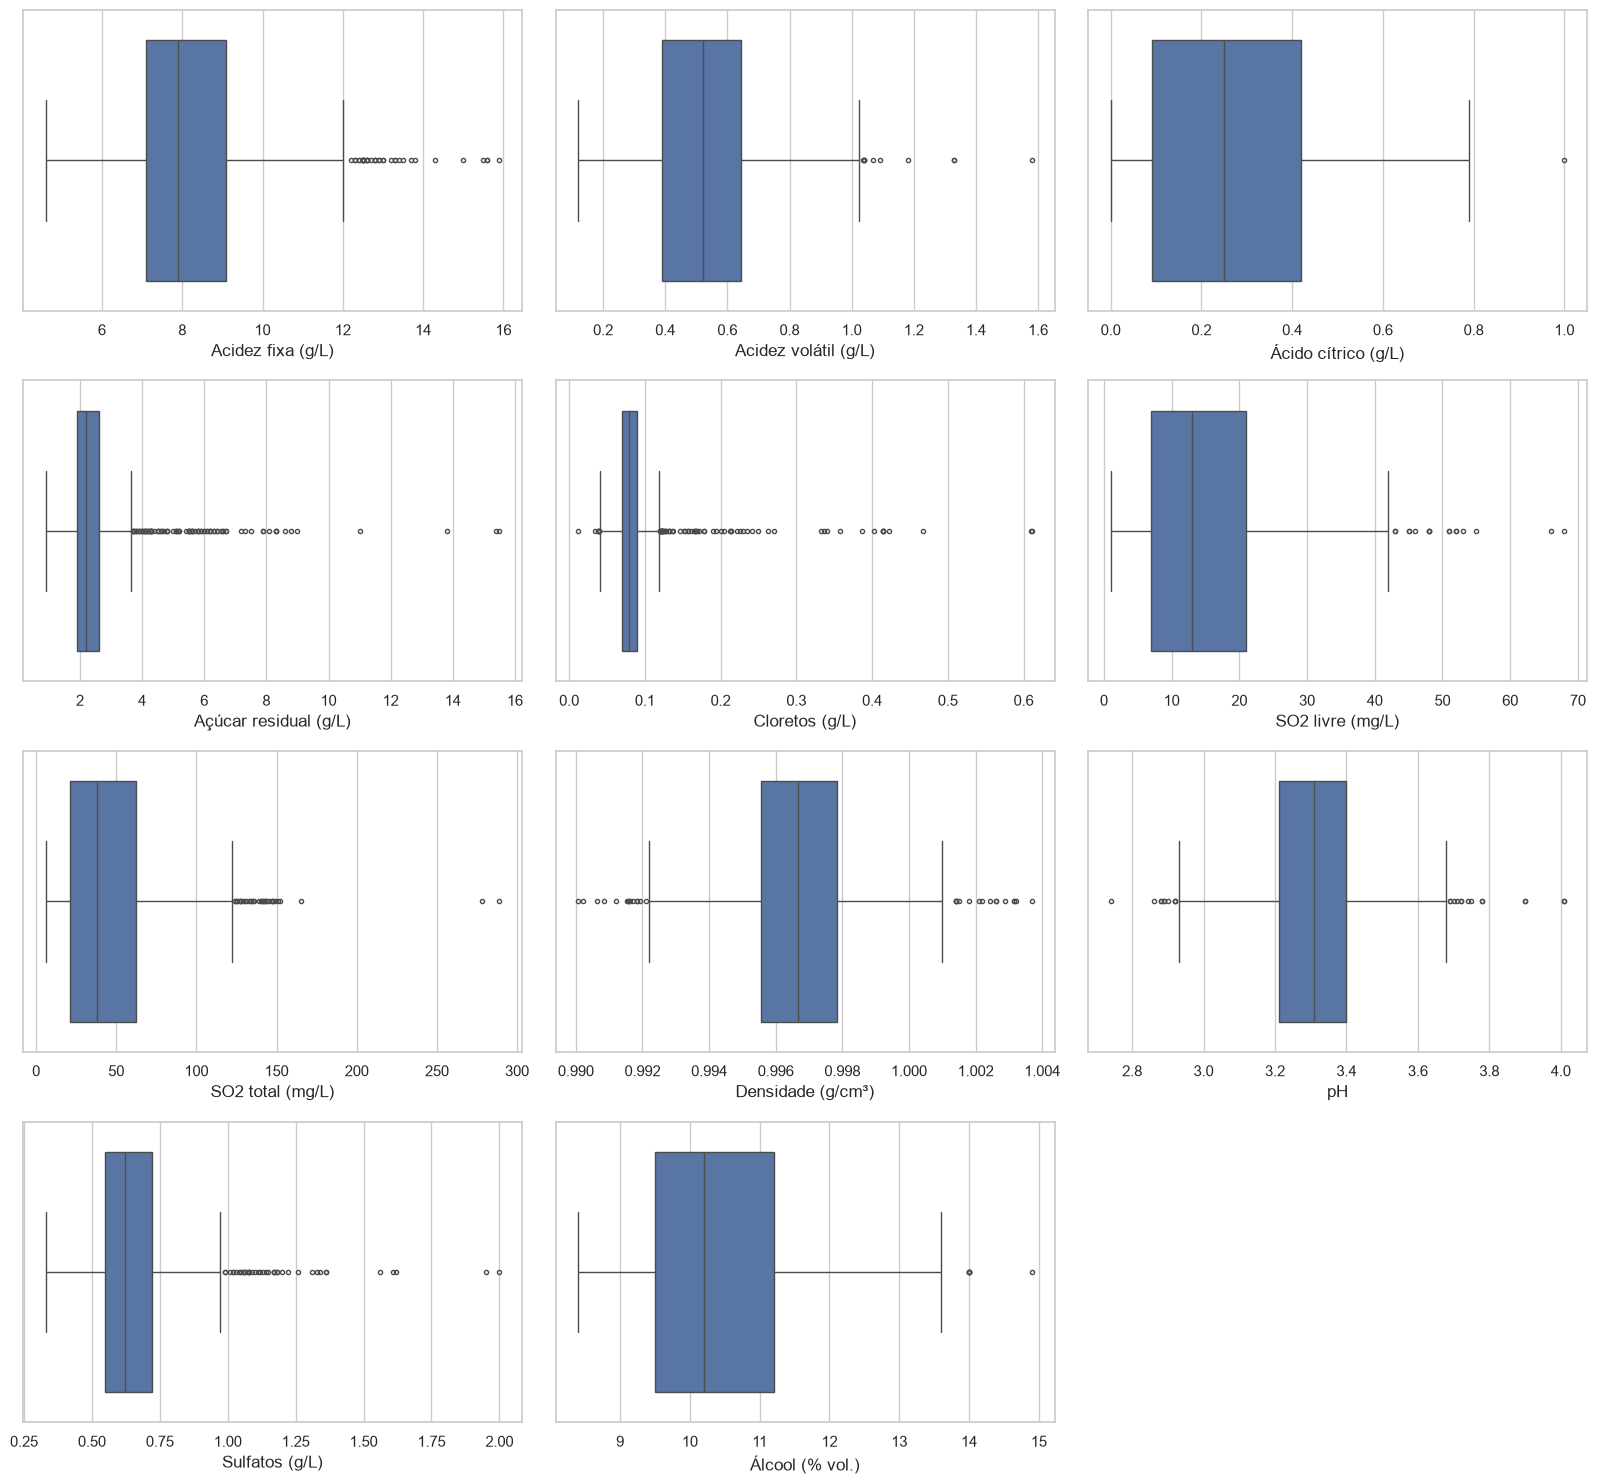

In [13]:
fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=df, x=col, ax=ax, fliersize=3)
    ax.set_xlabel(FEATURE_LABELS[col])
axes.flat[-1].axis('off')
fig.tight_layout()
save_fig(fig, '03_boxplots')
plt.show()

In [14]:
outliers = iqr_outliers(df)
outliers

,variavel,limite_inferior,limite_superior,outliers,percentual
0,residual sugar,0.8500,3.6500,95,9.3320
1,chlorides,0.0400,0.1200,71,6.9745
2,sulphates,0.2950,0.9750,41,4.0275
3,fixed acidity,4.1000,12.1000,37,3.6346
4,total sulfur dioxide,-40.5000,123.5000,33,3.2417
5,density,0.9922,1.0012,30,2.9470
6,pH,2.9250,3.6850,24,2.3576
7,free sulfur dioxide,-14.0000,42.0000,16,1.5717
8,volatile acidity,0.0075,1.0275,10,0.9823
9,alcohol,6.9500,13.7500,6,0.5894


In [15]:
mask = np.zeros(len(df), dtype=bool)
for _, row in outliers.iterrows():
    col = row['variavel']
    mask |= ((df[col] < row['limite_inferior']) | (df[col] > row['limite_superior'])).to_numpy()

print(f'Vinhos com pelo menos um outlier: {mask.sum()} ({mask.mean():.1%})')
print(f'Alta qualidade entre eles: {df.loc[mask, "high_quality"].mean():.1%}')
print(f'Alta qualidade na base toda: {df["high_quality"].mean():.1%}')

Vinhos com pelo menos um outlier: 262 (25.7%)
Alta qualidade entre eles: 17.6%
Alta qualidade na base toda: 13.5%


Decidimos manter os outliers. Eles não são erros de medição (nenhuma regra de consistência foi violada) e cerca de 26% dos vinhos têm pelo menos um valor extremo. Tirar esses vinhos seria perder um quarto da base, e justamente uma parte com mais vinhos de alta qualidade (17,6% contra 13,5% no geral). O Random Forest lida bem com outliers e, no KNN, vamos comparar dois tipos de escalonamento.

### Balanceamento das classes

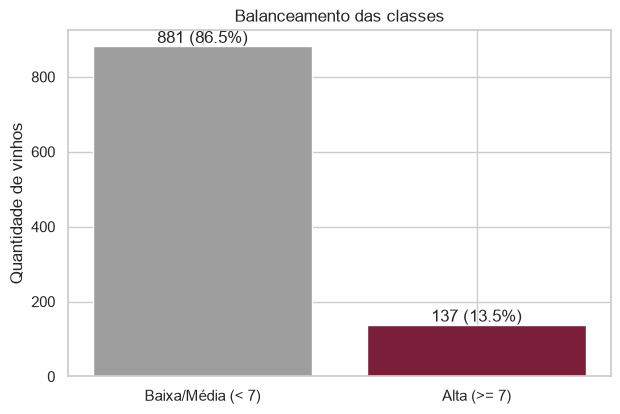

In [16]:
n_class = df['high_quality'].value_counts().sort_index()
pct_class = df['high_quality'].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(CLASSES, n_class.values, color=[COLORS[0], COLORS[1]])
ax.bar_label(bars, labels=[f'{n} ({p:.1%})' for n, p in zip(n_class, pct_class)])
ax.set_title('Balanceamento das classes')
ax.set_ylabel('Quantidade de vinhos')
save_fig(fig, '04_balanceamento')
plt.show()

Só 13,5% dos vinhos são de alta qualidade. Um modelo que chutasse "baixa/média" para todos teria 86,5% de acurácia sem acertar nenhum vinho bom, então a acurácia sozinha não serve para comparar os modelos. Por isso:

- usamos o F1 da classe alta como métrica principal, olhando também recall, precisão, ROC-AUC e PR-AUC;
- a divisão treino/teste e a validação cruzada são estratificadas (mantêm a proporção das classes);
- na Regressão Logística e no Random Forest usamos `class_weight='balanced'`, que dá mais peso aos erros na classe minoritária.

### Correlações

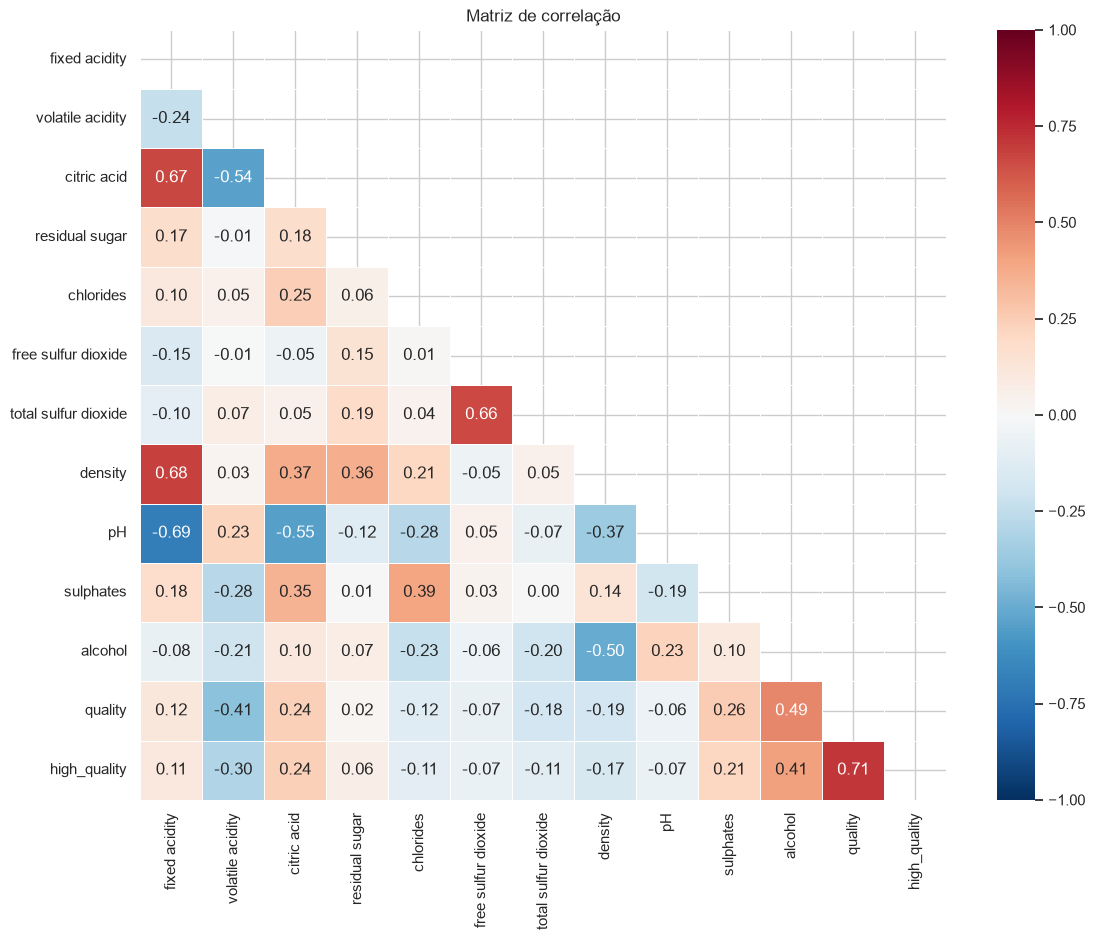

In [17]:
corr = df[FEATURES + ['quality', 'high_quality']].corr()

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title('Matriz de correlação')
save_fig(fig, '05_correlacao')
plt.show()

In [18]:
# pares de variáveis com correlação de pelo menos 0,3 (positiva ou negativa)
pairs = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        pairs.append((a, b, corr.loc[a, b]))

pairs = pd.DataFrame(pairs, columns=['variavel_1', 'variavel_2', 'r'])
pairs[pairs['r'].abs() >= 0.3].sort_values('r', key=abs, ascending=False)

,variavel_1,variavel_2,r
7,fixed acidity,pH,-0.6926
6,fixed acidity,density,0.6831
1,fixed acidity,citric acid,0.6682
40,free sulfur dioxide,total sulfur dioxide,0.6611
24,citric acid,pH,-0.5534
10,volatile acidity,citric acid,-0.5425
51,density,alcohol,-0.5047
38,chlorides,sulphates,0.3930
23,citric acid,density,0.3688
49,density,pH,-0.3662


Justificativa de cada correlação:

| Par | r | Por que acontece |
|---|---|---|
| Acidez fixa x pH | -0,69 | Quanto mais ácido, menor o pH. É a definição de pH. |
| Acidez fixa x densidade | 0,68 | Os ácidos dissolvidos deixam o vinho mais denso que a água. |
| Acidez fixa x ácido cítrico | 0,67 | O ácido cítrico é um dos ácidos fixos, então entra na conta da acidez fixa. |
| SO2 livre x SO2 total | 0,66 | O SO2 total é a soma do livre com o combinado. |
| Ácido cítrico x pH | -0,55 | Mesmo motivo da acidez fixa: mais ácido, pH menor. |
| Acidez volátil x ácido cítrico | -0,54 | Bactérias podem transformar o ácido cítrico em ácido acético, que é o principal componente da acidez volátil. |
| Densidade x álcool | -0,50 | O álcool é mais leve que a água, e ele vem da fermentação do açúcar, que é mais pesado. |
| Cloretos x sulfatos | 0,39 | Os dois são sais minerais e vêm da uva, do solo e do processo. |
| Densidade x pH | -0,37 | Efeito indireto: vinhos mais ácidos são mais densos e têm pH menor. |
| Ácido cítrico x densidade | 0,37 | Mais substância dissolvida, mais densidade. |
| Açúcar residual x densidade | 0,36 | Açúcar dissolvido aumenta a densidade (por isso a densidade é usada para acompanhar a fermentação). |
| Ácido cítrico x sulfatos | 0,35 | Provavelmente ligado ao processo: correção de acidez e adição de sulfitos costumam andar juntas. |

Acidez fixa, ácido cítrico, pH e densidade formam um grupo de variáveis ligadas entre si (multicolinearidade). Isso não atrapalha o KNN nem o Random Forest, mas pode dividir o efeito entre elas nos coeficientes da Regressão Logística.

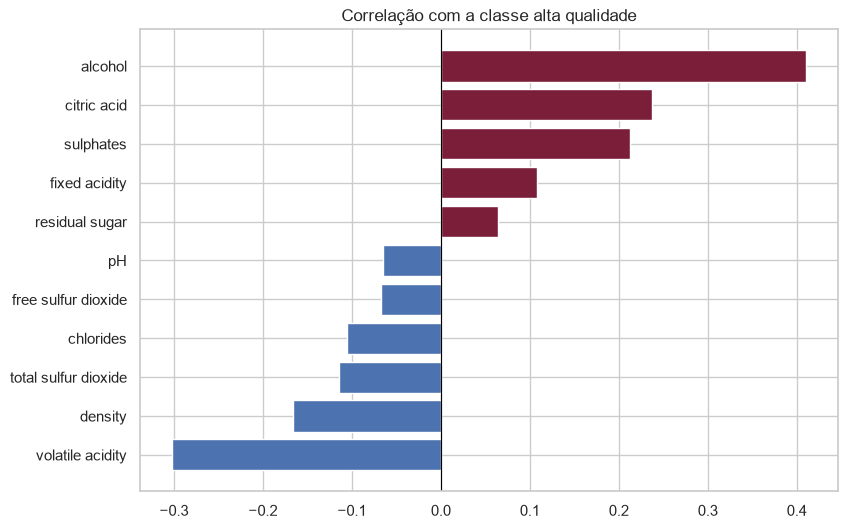

In [19]:
target_corr = df[FEATURES + ['high_quality']].corr()['high_quality'].drop('high_quality').sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(target_corr.index, target_corr.values,
        color=[COLORS[1] if v > 0 else '#4c72b0' for v in target_corr.values])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Correlação com a classe alta qualidade')
save_fig(fig, '06_correlacao_alvo')
plt.show()

Em relação à qualidade:

| Variável | r | Por que acontece |
|---|---|---|
| Álcool | 0,41 | Mais álcool indica uva mais madura e vinho mais encorpado, o que costuma ser bem avaliado. |
| Acidez volátil | -0,30 | É basicamente ácido acético. Em excesso deixa o vinho com cheiro e gosto de vinagre. |
| Ácido cítrico | 0,24 | Dá frescor e, como vimos, anda junto com menos acidez volátil. |
| Sulfatos | 0,21 | Contribuem para o SO2, que protege o vinho contra oxidação e micro-organismos. |
| Densidade | -0,17 | Efeito indireto do álcool (mais álcool, menor densidade). |
| SO2 total e cloretos | -0,11 | SO2 em excesso prejudica o aroma; cloretos deixam o vinho salgado. |
| Açúcar residual, SO2 livre e pH | perto de 0 | Quase nenhuma relação linear com a qualidade. |

Nenhuma variável sozinha explica bem a qualidade (a maior correlação é 0,41), então faz sentido usar modelos que combinam várias variáveis.

### Comparação entre as classes

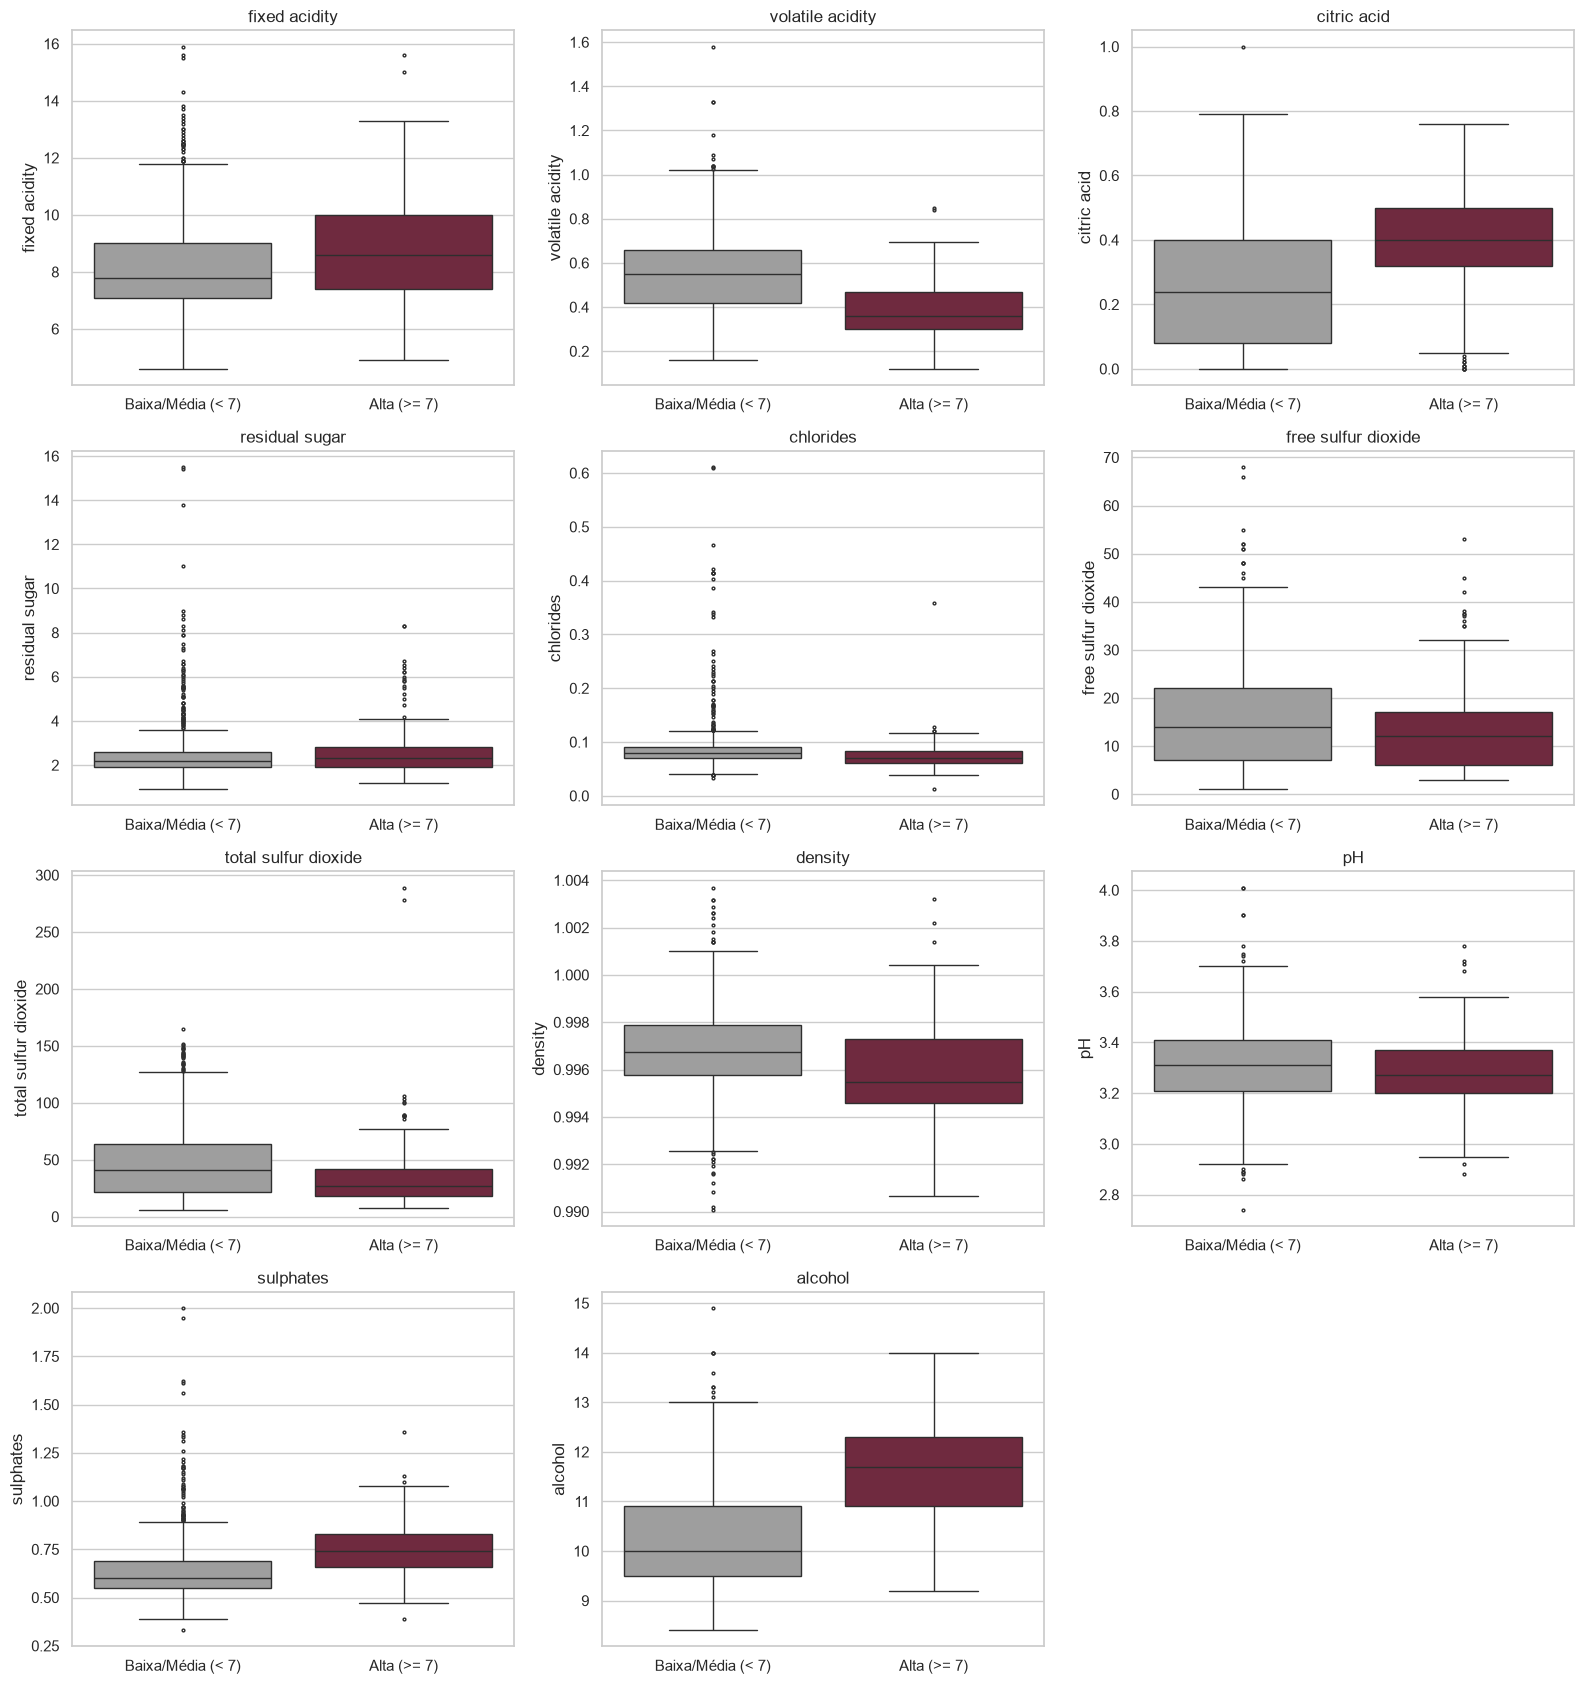

In [20]:
fig, axes = plt.subplots(4, 3, figsize=(16, 17))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=df, x='high_quality', y=col, hue='high_quality', palette=COLORS,
                legend=False, ax=ax, fliersize=2)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(CLASSES)
    ax.set_xlabel('')
    ax.set_title(col)
axes.flat[-1].axis('off')
fig.tight_layout()
save_fig(fig, '07_boxplots_por_classe')
plt.show()

In [21]:
means = df.groupby('high_quality')[FEATURES].mean().T
means.columns = CLASSES
means['diferença %'] = (means[CLASSES[1]] / means[CLASSES[0]] - 1) * 100
means.sort_values('diferença %', key=abs, ascending=False)

,Baixa/Média (< 7),Alta (>= 7),diferença %
citric acid,0.2504,0.3869,54.4710
volatile acidity,0.5554,0.3932,-29.2047
total sulfur dioxide,47.8269,36.6715,-23.3245
chlorides,0.0892,0.0742,-16.8163
sulphates,0.6427,0.7473,16.2665
alcohol,10.2753,11.5914,12.8075
free sulfur dioxide,15.9188,13.9124,-12.6041
residual sugar,2.4910,2.7391,9.9564
fixed acidity,8.2144,8.7650,6.7022
pH,3.3156,3.2854,-0.9097


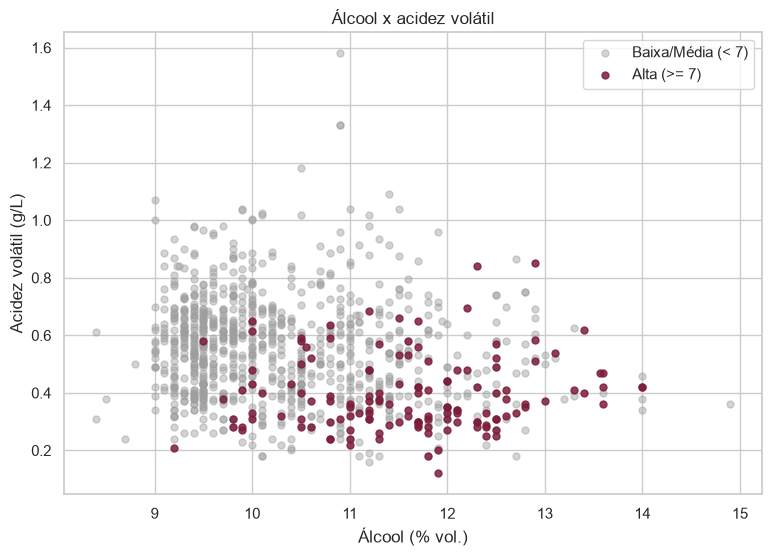

In [22]:
fig, ax = plt.subplots(figsize=(9, 6))
for c in [0, 1]:
    sub = df[df['high_quality'] == c]
    ax.scatter(sub['alcohol'], sub['volatile acidity'], c=COLORS[c], s=25,
               alpha=0.45 if c == 0 else 0.85, label=CLASSES[c])
ax.set_xlabel(FEATURE_LABELS['alcohol'])
ax.set_ylabel(FEATURE_LABELS['volatile acidity'])
ax.set_title('Álcool x acidez volátil')
ax.legend()
save_fig(fig, '08_alcool_vs_acidez_volatil')
plt.show()

Os vinhos de alta qualidade se concentram na parte de baixo e à direita do gráfico: mais álcool e menos acidez volátil. Também chama atenção que os dois valores mais altos de SO2 total da base (por volta de 280 e 290) são de vinhos de alta qualidade.

### Resumo da análise exploratória

- A base não tem dados faltantes nem valores inconsistentes, mas tinha 125 duplicadas (11%). Depois de remover, ficamos com 1.018 vinhos.
- Só 13,5% dos vinhos são de alta qualidade (137), então a acurácia sozinha engana.
- O álcool é o que mais diferencia as classes: média de 11,6% nos vinhos bons contra 10,3% nos demais.
- A acidez volátil é 29% menor nos vinhos bons (0,39 contra 0,56 g/L).
- Ácido cítrico (55% maior) e sulfatos (16% maior) também aparecem mais nos vinhos bons, e o SO2 total é 23% menor.
- Açúcar residual, pH e SO2 livre quase não mudam entre as classes.
- Acidez fixa, ácido cítrico, pH e densidade são bem correlacionados entre si, o que faz sentido pela química do vinho.

## 3. Pré-processamento

Não temos dados faltantes, então não precisamos de imputação.

### Novas variáveis

Criamos três variáveis a partir das existentes:

- `total acidity`: acidez fixa + acidez volátil + ácido cítrico
- `volatile acidity ratio`: parte da acidez total que é volátil (o "defeito")
- `free so2 ratio`: parte do SO2 total que está livre, ou seja, ativa protegendo o vinho

Elas são calculadas com os valores do próprio vinho, linha a linha, então não causam vazamento de dados. Mais abaixo testamos se elas ajudam os modelos.

In [23]:
df = add_engineered_features(df)
df[ENGINEERED_FEATURES + ['high_quality']].corr()['high_quality'].drop('high_quality')

total acidity             0.0976
volatile acidity ratio   -0.2726
free so2 ratio            0.1251
Name: high_quality, dtype: float64

### Divisão treino e teste

Separamos 80% para treino e 20% para teste com `stratify=y`, para os dois conjuntos ficarem com a mesma proporção de vinhos bons. O teste só é usado uma vez, no final. Todas as escolhas (variáveis, valor de k, hiperparâmetros) são feitas com validação cruzada dentro do treino.

In [24]:
ALL_FEATURES = FEATURES + ENGINEERED_FEATURES
X = df[ALL_FEATURES]
y = df['high_quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pd.DataFrame({'amostras': [len(y_train), len(y_test)],
              'alta qualidade': [y_train.sum(), y_test.sum()],
              'proporção': [y_train.mean(), y_test.mean()]},
             index=['treino', 'teste'])

,amostras,alta qualidade,proporção
treino,814,110,0.1351
teste,204,27,0.1324


### Escalonamento

O escalonamento fica dentro de um `Pipeline` junto com o modelo. Assim, em cada rodada da validação cruzada o scaler aprende os parâmetros só com a parte de treino daquela rodada, e no teste ele apenas aplica a transformação. Fazer o `fit` do scaler na base inteira antes de dividir seria vazamento de dados.

Testamos duas opções no KNN:

- normalização Min-Max: `(x - min) / (max - min)`, deixa tudo entre 0 e 1
- padronização: `(x - média) / desvio padrão`, deixa média 0 e desvio 1

A Regressão Logística usa padronização. O Random Forest não precisa de escalonamento, porque cada árvore só compara uma variável de cada vez com um valor de corte.

### As novas variáveis ajudam?

Comparamos, com validação cruzada de 5 folds no treino, os modelos usando só as 11 variáveis originais e usando as 14.

In [25]:
cv = get_cv()

base_models = {'KNN (k=15)': knn_pipeline(15),
               'Regressão Logística': logreg_pipeline(),
               'Random Forest': rf_pipeline()}

rows = []
for set_name, cols in {'originais': FEATURES, 'com novas': ALL_FEATURES}.items():
    for name, model in base_models.items():
        res = cv_summary(clone(model), X_train[cols], y_train, cv)
        rows.append({'modelo': name, 'variáveis': set_name, 'f1': res['f1']})

fe = pd.DataFrame(rows).pivot(index='modelo', columns='variáveis', values='f1')
fe['ganho'] = fe['com novas'] - fe['originais']
fe

variáveis,com novas,originais,ganho
modelo,,,
KNN (k=15),0.3927,0.3317,0.0611
Random Forest,0.5212,0.5046,0.0166
Regressão Logística,0.5166,0.5185,-0.0019


In [26]:
USE_NEW = fe['ganho'].mean() > 0
SELECTED = ALL_FEATURES if USE_NEW else FEATURES
print('Ganho médio de F1:', round(fe['ganho'].mean(), 4))
print('Variáveis usadas:', len(SELECTED))

X_train, X_test = X_train[SELECTED], X_test[SELECTED]

Ganho médio de F1: 0.0253
Variáveis usadas: 14


As novas variáveis melhoraram o KNN e um pouco o Random Forest, e praticamente não mudaram a Regressão Logística. Como o ganho médio foi positivo, seguimos com as 14 variáveis.

## 4. Modelos

Testamos três modelos de classificação supervisionada:

- KNN: classifica o vinho olhando a classe dos k vinhos mais parecidos com ele no treino.
- Regressão Logística: combina as variáveis em uma soma com pesos e transforma o resultado em uma probabilidade de ser de alta qualidade.
- Random Forest: várias árvores de decisão treinadas com amostras e variáveis aleatórias, que votam no resultado final.

Os hiperparâmetros de cada um são escolhidos pelo F1 da classe alta na validação cruzada. Como referência, também calculamos um baseline que sempre responde a classe majoritária.

In [27]:
baseline = DummyClassifier(strategy='most_frequent')
base_cv = cv_summary(baseline, X_train, y_train, cv)
print(f"Baseline: acurácia {base_cv['accuracy']:.3f} | F1 {base_cv['f1']:.3f}")

Baseline: acurácia 0.865 | F1 0.000


### KNN: escolhendo o k

Testamos k ímpar de 1 a 51 (ímpar para não dar empate na votação) com os dois tipos de escalonamento e guardamos as métricas da validação cruzada de cada combinação.

In [28]:
knn_rows = []
for scaler in SCALERS:
    for k in range(1, 52, 2):
        scores = cross_validate(knn_pipeline(k, scaler), X_train, y_train, cv=cv, n_jobs=-1,
                                scoring={'accuracy': 'accuracy', 'f1': SCORING['f1'],
                                         'recall': 'recall', 'precision': SCORING['precision']})
        knn_rows.append({'scaler': scaler, 'k': k,
                         'accuracy': scores['test_accuracy'].mean(),
                         'f1': scores['test_f1'].mean(),
                         'recall': scores['test_recall'].mean(),
                         'precision': scores['test_precision'].mean()})

knn_results = pd.DataFrame(knn_rows)
knn_results.to_csv('results/knn_busca_k.csv', index=False)

best_f1 = knn_results.loc[knn_results['f1'].idxmax()]
best_acc = knn_results.loc[knn_results['accuracy'].idxmax()]
print('Melhor pelo F1:')
print(best_f1.to_frame().T)
print('Melhor pela acurácia:')
print(best_acc.to_frame().T)

Melhor pelo F1:
   scaler  k accuracy     f1 recall precision
3  MinMax  7   0.8869 0.4926 0.4091    0.6228
Melhor pela acurácia:
      scaler   k accuracy     f1 recall precision
34  Standard  17   0.8882 0.4210 0.3091    0.6882


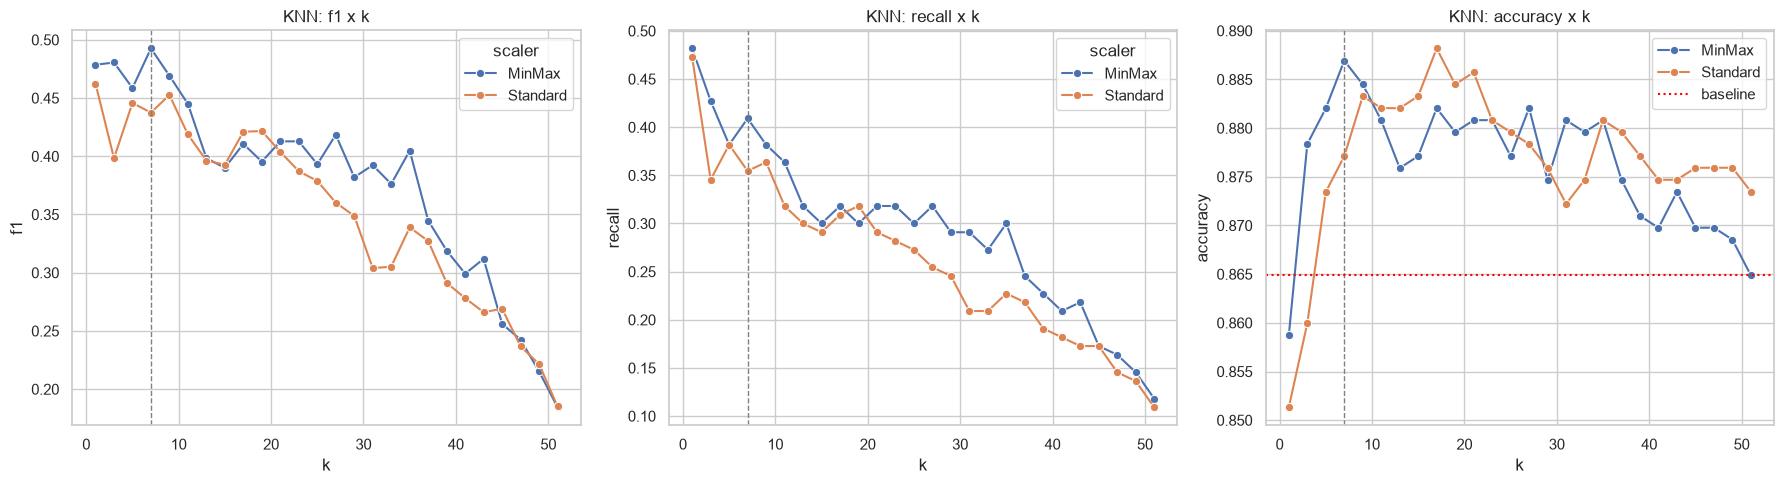

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ['f1', 'recall', 'accuracy']):
    sns.lineplot(data=knn_results, x='k', y=metric, hue='scaler', marker='o', ax=ax)
    ax.axvline(best_f1['k'], color='gray', linestyle='--', linewidth=1)
    ax.set_title(f'KNN: {metric} x k')
axes[2].axhline(base_cv['accuracy'], color='red', linestyle=':', label='baseline')
axes[2].legend()
fig.tight_layout()
save_fig(fig, '09_knn_escolha_k')
plt.show()

Conforme o k aumenta, o KNN passa a seguir a maioria e prevê cada vez menos vinhos como bons. A acurácia continua alta, mas o recall e o F1 caem. Se escolhêssemos pela acurácia, ficaríamos com k=17 (padronização), que tem F1 de 0,42 e recall de 0,31. Pelo F1, o escolhido foi k=7 com Min-Max, com F1 de 0,49 e recall de 0,41.

O Min-Max foi melhor que a padronização na maioria dos valores de k. Uma explicação possível é que, nas variáveis com cauda longa (cloretos, açúcar residual), o Min-Max espreme quase todos os vinhos em uma faixa pequena e com isso essas variáveis, que pouco têm a ver com a qualidade, pesam menos na distância.

In [30]:
knn = knn_pipeline(int(best_f1['k']), best_f1['scaler']).fit(X_train, y_train)

### Regressão Logística

Ajustamos o `C`, que controla a regularização (quanto menor, mais simples o modelo).

In [31]:
grid_lr = GridSearchCV(logreg_pipeline(), {'model__C': [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]},
                       scoring=SCORING['f1'], cv=cv, n_jobs=-1)
grid_lr.fit(X_train, y_train)
logreg = grid_lr.best_estimator_
print(grid_lr.best_params_, round(grid_lr.best_score_, 3))

{'model__C': 0.1} 0.525


### Random Forest

Ajustamos a profundidade máxima das árvores, o mínimo de amostras por folha e quantas variáveis cada divisão pode considerar.

In [32]:
grid_rf = GridSearchCV(rf_pipeline(),
                       {'model__max_depth': [None, 5, 10],
                        'model__min_samples_leaf': [1, 3, 5],
                        'model__max_features': ['sqrt', 0.5]},
                       scoring=SCORING['f1'], cv=cv, n_jobs=-1)
grid_rf.fit(X_train, y_train)
rf = grid_rf.best_estimator_
print(grid_rf.best_params_, round(grid_rf.best_score_, 3))

{'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5} 0.551


### Comparação na validação cruzada

Média e desvio padrão dos 5 folds, já com os hiperparâmetros escolhidos.

In [33]:
models = {'KNN': knn, 'Regressão Logística': logreg, 'Random Forest': rf}

cv_rows = {}
for name, model in {'Baseline': baseline, **models}.items():
    cv_rows[name] = cv_summary(clone(model), X_train, y_train, cv)

cv_results = pd.DataFrame(cv_rows).T
cv_results.to_csv('results/metricas_validacao_cruzada.csv')

pd.DataFrame({METRIC_NAMES[m]: cv_results[m].map('{:.3f}'.format) + ' ± ' + cv_results[m + '_std'].map('{:.3f}'.format)
              for m in SCORING})

,Acurácia,Acurácia balanceada,Precisão,Recall,F1,ROC-AUC,PR-AUC
Baseline,0.865 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.135 ± 0.000
KNN,0.887 ± 0.026,0.685 ± 0.060,0.623 ± 0.140,0.409 ± 0.108,0.493 ± 0.120,0.812 ± 0.057,0.468 ± 0.122
Regressão Logística,0.796 ± 0.009,0.813 ± 0.034,0.383 ± 0.017,0.836 ± 0.074,0.525 ± 0.029,0.882 ± 0.029,0.555 ± 0.107
Random Forest,0.834 ± 0.025,0.801 ± 0.055,0.435 ± 0.054,0.755 ± 0.106,0.551 ± 0.068,0.877 ± 0.040,0.561 ± 0.144


In [34]:
best_name = cv_results.drop(index='Baseline')['f1'].idxmax()
print('Melhor F1 na validação cruzada:', best_name)

Melhor F1 na validação cruzada: Random Forest


## 5. Avaliação no teste

Agora usamos o conjunto de teste, que nenhum modelo viu até aqui. A métrica principal continua sendo o F1 da classe alta; a acurácia aparece só como referência.

In [35]:
baseline.fit(X_train, y_train)
all_models = {'Baseline': baseline, **models}

test_results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in all_models.items()}).T
test_results.columns = [METRIC_NAMES[c] for c in test_results.columns]
test_results.to_csv('results/metricas_teste.csv')
test_results

,Acurácia,Acurácia balanceada,Precisão,Recall,F1,ROC-AUC,PR-AUC
Baseline,0.8676,0.5000,0.0000,0.0000,0.0000,0.5000,0.1324
KNN,0.9118,0.7451,0.7368,0.5185,0.6087,0.8649,0.5271
Regressão Logística,0.7892,0.7687,0.3571,0.7407,0.4819,0.8860,0.4840
Random Forest,0.8235,0.7884,0.4082,0.7407,0.5263,0.9217,0.7142


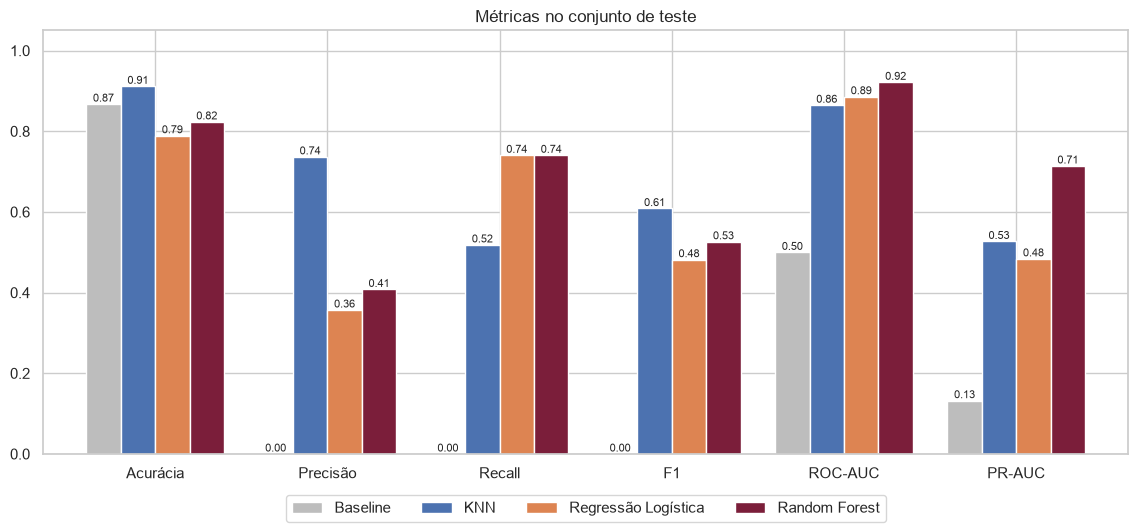

In [36]:
cols = ['Acurácia', 'Precisão', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']

fig, ax = plt.subplots(figsize=(14, 5.5))
test_results[cols].T.plot.bar(ax=ax, width=0.8, color=['#bdbdbd', '#4c72b0', '#dd8452', '#7b1e3a'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=8)
ax.set_xticklabels(cols, rotation=0)
ax.set_ylim(0, 1.05)
ax.set_title('Métricas no conjunto de teste')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=4)
save_fig(fig, '10_metricas_teste')
plt.show()

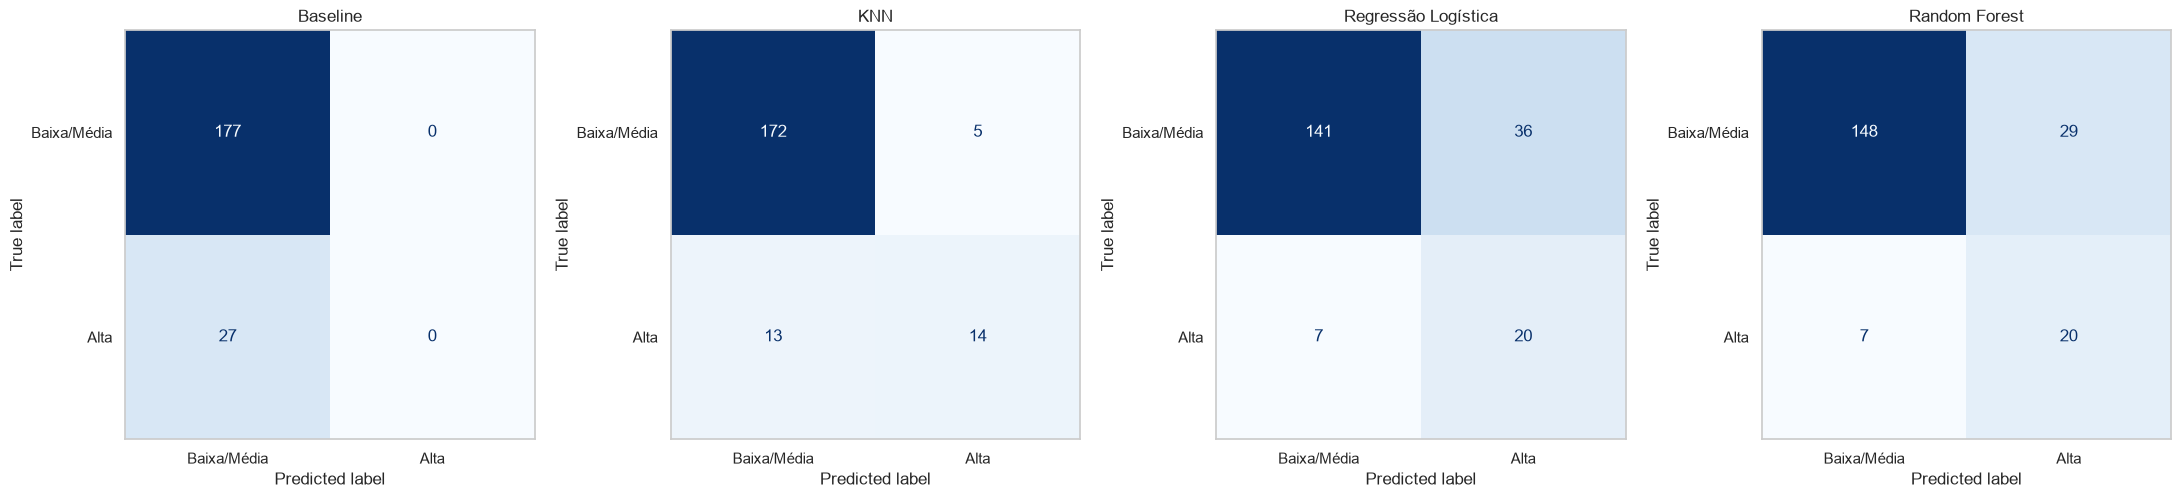

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (name, model) in zip(axes, all_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['Baixa/Média', 'Alta'],
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
fig.tight_layout()
save_fig(fig, '11_matrizes_confusao')
plt.show()

In [38]:
for name, model in all_models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test)).ravel()
    print(f'{name}: acertou {tp} de {tp + fn} vinhos bons, {fp} falsos alarmes')

Baseline: acertou 0 de 27 vinhos bons, 0 falsos alarmes
KNN: acertou 14 de 27 vinhos bons, 5 falsos alarmes
Regressão Logística: acertou 20 de 27 vinhos bons, 36 falsos alarmes
Random Forest: acertou 20 de 27 vinhos bons, 29 falsos alarmes


In [39]:
for name, model in models.items():
    print(name)
    print(classification_report(y_test, model.predict(X_test), target_names=CLASSES, digits=3))

KNN
                   precision    recall  f1-score   support

Baixa/Média (< 7)      0.930     0.972     0.950       177
      Alta (>= 7)      0.737     0.519     0.609        27

         accuracy                          0.912       204
        macro avg      0.833     0.745     0.779       204
     weighted avg      0.904     0.912     0.905       204

Regressão Logística
                   precision    recall  f1-score   support

Baixa/Média (< 7)      0.953     0.797     0.868       177
      Alta (>= 7)      0.357     0.741     0.482        27

         accuracy                          0.789       204
        macro avg      0.655     0.769     0.675       204
     weighted avg      0.874     0.789     0.817       204

Random Forest


                   precision    recall  f1-score   support

Baixa/Média (< 7)      0.955     0.836     0.892       177
      Alta (>= 7)      0.408     0.741     0.526        27

         accuracy                          0.824       204
        macro avg      0.682     0.788     0.709       204
     weighted avg      0.882     0.824     0.843       204



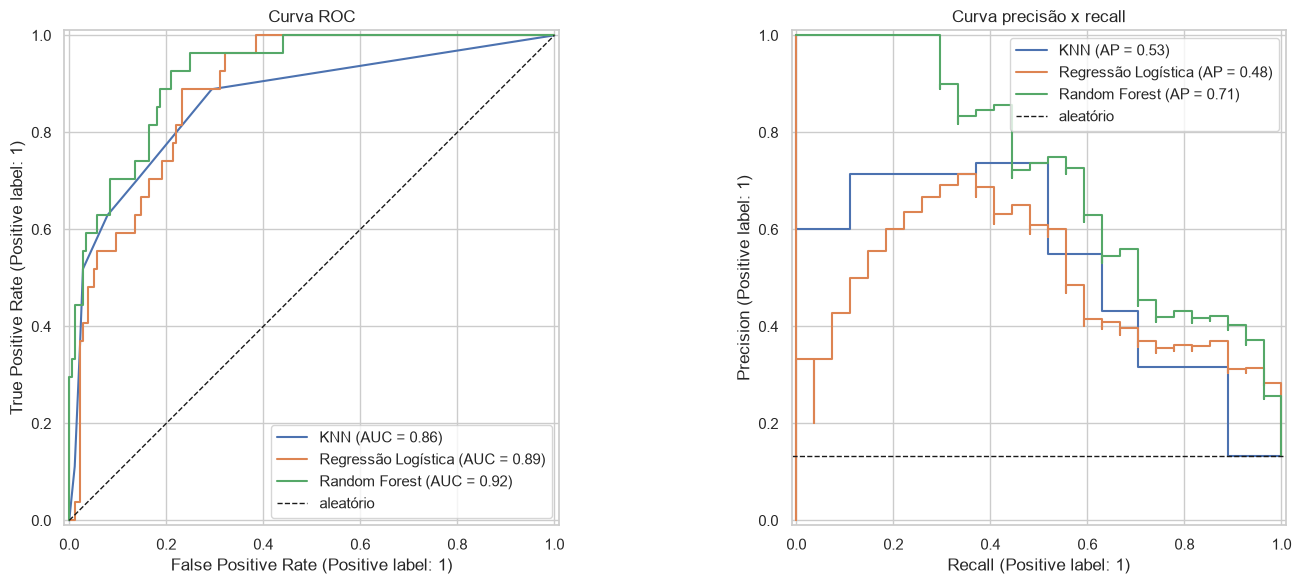

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='aleatório')
axes[0].legend(loc='lower right')
axes[0].set_title('Curva ROC')
axes[1].axhline(y_test.mean(), color='k', linestyle='--', linewidth=1, label='aleatório')
axes[1].legend(loc='upper right')
axes[1].set_title('Curva precisão x recall')
fig.tight_layout()
save_fig(fig, '12_curvas_roc_pr')
plt.show()

### Comparação final

Todos os modelos ficaram bem acima do baseline, que tem 86,8% de acurácia mas não encontra nenhum vinho bom.

Escolhemos o Random Forest. Ele teve o maior F1 na validação cruzada (0,55) e, no teste, foi o que melhor ordenou os vinhos pela probabilidade de serem bons (ROC-AUC de 0,92 e PR-AUC de 0,71). Ele encontrou 20 dos 27 vinhos de alta qualidade do teste.

O KNN teve o maior F1 no teste (0,61), mas foi o pior na validação cruzada (0,49) e o que mais variou entre os folds. Como o teste tem só 27 vinhos bons, acertar um ou dois a mais muda bastante o F1. Por isso confiamos mais na validação cruzada, e escolher o modelo olhando o teste faria o teste deixar de ser uma avaliação independente.

Os modelos também se comportam de formas diferentes. O KNN é mais conservador: dá poucos falsos alarmes (5), mas deixa passar metade dos vinhos bons. O Random Forest e a Regressão Logística, com `class_weight='balanced'`, encontram 74% dos vinhos bons, mas com mais falsos alarmes (29 e 36). Qual comportamento é melhor depende do negócio: se o importante é não perder nenhum lote com potencial, vale mais o recall; se analisar cada lote sinalizado custa caro, vale mais a precisão. No Random Forest dá para ajustar isso mudando o limite de probabilidade (0,5 por padrão), sem treinar de novo.

## 6. Interpretação dos resultados

Para ver quais variáveis mais influenciam a qualidade, usamos a importância das variáveis do Random Forest e os coeficientes da Regressão Logística. Como as variáveis da Regressão Logística estão padronizadas, os coeficientes podem ser comparados entre si, e o sinal indica se a variável aumenta ou diminui a chance de o vinho ser bom.

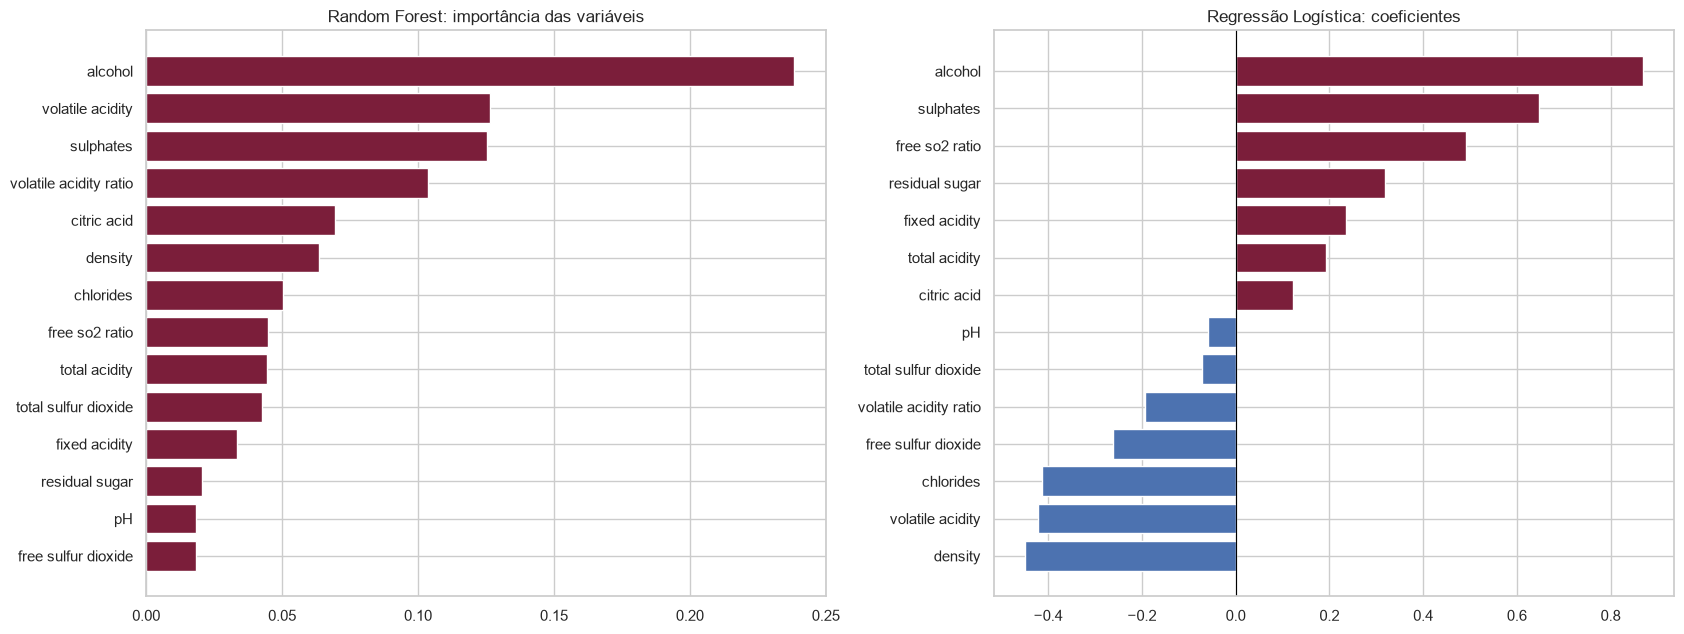

In [41]:
rf_imp = pd.Series(rf.named_steps['model'].feature_importances_, index=SELECTED).sort_values()
lr_coef = pd.Series(logreg.named_steps['model'].coef_[0], index=SELECTED).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
axes[0].barh(rf_imp.index, rf_imp.values, color=COLORS[1])
axes[0].set_title('Random Forest: importância das variáveis')
axes[1].barh(lr_coef.index, lr_coef.values,
             color=[COLORS[1] if v > 0 else '#4c72b0' for v in lr_coef.values])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Regressão Logística: coeficientes')
fig.tight_layout()
save_fig(fig, '13_importancia_variaveis')
plt.show()

In [42]:
importance = pd.DataFrame({'rf_importancia': rf_imp, 'rl_coeficiente': lr_coef,
                           'rl_odds_ratio': np.exp(lr_coef)}).sort_values('rf_importancia', ascending=False)
importance.to_csv('results/importancia_variaveis.csv')
importance

,rf_importancia,rl_coeficiente,rl_odds_ratio
alcohol,0.2382,0.8693,2.3852
volatile acidity,0.1263,-0.4224,0.6555
sulphates,0.1255,0.6481,1.9120
volatile acidity ratio,0.1037,-0.1925,0.8249
citric acid,0.0694,0.1226,1.1304
density,0.0635,-0.4496,0.6379
chlorides,0.0505,-0.4141,0.6610
free so2 ratio,0.0448,0.4919,1.6354
total acidity,0.0446,0.1932,1.2131
total sulfur dioxide,0.0426,-0.0723,0.9302


O álcool é a variável mais importante nos dois modelos. Na Regressão Logística, o odds ratio de 2,4 quer dizer que cada desvio padrão a mais de álcool multiplica por 2,4 a chance de o vinho ser de alta qualidade.

Logo depois vêm os sulfatos (efeito positivo) e a acidez volátil (efeito negativo). A proporção de acidez volátil, uma das variáveis que criamos, também aparece bem no Random Forest e reforça o papel da acidez volátil. Na Regressão Logística, a proporção de SO2 livre tem efeito positivo: quanto maior a parte do SO2 que está ativa protegendo o vinho, melhor.

O ácido cítrico, que tinha uma diferença grande entre as classes na análise exploratória, perde importância nos modelos. Como ele é bem correlacionado com a acidez volátil (-0,54), boa parte da informação dele já está nela. pH e SO2 total estão entre as variáveis que menos influenciam.

### O que isso significa para a produção

1. Maturação e fermentação: como o álcool é o fator mais ligado à qualidade, colher a uva no ponto certo de maturação e garantir uma fermentação completa são pontos importantes.
2. Controle da acidez volátil: ela indica contaminação por bactérias acéticas ou oxidação. Higiene, controle de temperatura, menos contato com oxigênio e uso correto de SO2 ajudam. Vale acompanhar a acidez volátil como um alerta ao longo do processo.
3. Uso equilibrado de sulfatos e SO2: sulfatos em nível adequado ajudam, mas SO2 total alto aparece mais nos vinhos piores. O que importa é a proteção ser eficiente (mais SO2 livre em proporção ao total), usando a menor dose que funcione e respeitando os limites legais.
4. Triagem de lotes: com as análises de laboratório que já são feitas, o modelo pode apontar os lotes com mais potencial (para uma linha premium ou para priorizar a avaliação sensorial) e os lotes com risco (para corrigir antes). Ele não substitui os especialistas, mas ajuda a direcionar o trabalho deles.

### Limitações

- Os modelos mostram associações, não causa e efeito. Qualquer mudança no processo precisa ser testada antes.
- A base tem só vinhos tintos de uma região (Vinho Verde, Portugal) e apenas 137 vinhos de alta qualidade.
- Faltam informações que certamente influenciam a qualidade, como tipo de uva, safra e tempo de envelhecimento.
- A nota vem de avaliação sensorial e varia de um avaliador para outro.

## 7. Conclusão

In [43]:
r = test_results.loc[best_name]
print(f'Vinhos analisados: {len(df)} ({y.mean():.1%} de alta qualidade)')
print(f'Modelo escolhido: {best_name}')
print(f"Teste: F1 {r['F1']:.3f} | recall {r['Recall']:.3f} | precisão {r['Precisão']:.3f} | ROC-AUC {r['ROC-AUC']:.3f}")
print('Variáveis mais importantes (RF):', ', '.join(rf_imp.sort_values(ascending=False).index[:3]))

Vinhos analisados: 1018 (13.5% de alta qualidade)
Modelo escolhido: Random Forest
Teste: F1 0.526 | recall 0.741 | precisão 0.408 | ROC-AUC 0.922
Variáveis mais importantes (RF): alcohol, volatile acidity, sulphates


Transformar a nota em duas classes deixou o problema desbalanceado, com só 13,5% de vinhos bons. Por isso usamos F1, recall, precisão e as curvas ROC e precisão x recall em vez de olhar só a acurácia, além de divisão estratificada e pesos por classe.

Tomamos cuidado com vazamento de dados em todas as etapas: removemos as duplicadas, separamos o teste antes de qualquer ajuste, deixamos o escalonamento dentro do pipeline e escolhemos os hiperparâmetros só com validação cruzada no treino.

O Random Forest foi o modelo escolhido. No teste ele encontrou 74% dos vinhos de alta qualidade, com ROC-AUC de 0,92. O KNN pode ser uma alternativa quando o mais importante é ter poucos falsos alarmes.

Álcool, sulfatos e acidez volátil foram as variáveis que mais influenciaram a qualidade, o que aponta para maturação e fermentação, controle de contaminação e uso equilibrado de conservantes como os pontos principais do processo.

Os gráficos e as métricas estão salvos na pasta `results/`.